# Временной анализ климатических данных

**Задача:** построить базовый прогноз среднемесячной температуры в Нидерландах по данным *Climate Change: Earth Surface Temperature Data* и оценить его качество.

В ноутбуке последовательно выполняются подготовка ряда, хронологическое holdout-разбиение, rolling-window-разбиение, генерация признаков и обучение линейной регрессии.

In [21]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
)

pd.set_option("display.max_columns", 20)
plt.rcParams.update({
    "figure.figsize": (14, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

DATA_PATH = Path("data") / "GlobalLandTemperaturesByCountry.csv"
COUNTRY = "Netherlands"

## 1. Подготовка данных

Оставляем наблюдения по Нидерландам, преобразуем `dt` в дату и делаем его индексом. Частота `MS` означает один месячный шаг по первому дню месяца.

In [22]:
country_df = pd.read_csv(
    DATA_PATH,
    usecols=["dt", "AverageTemperature", "Country"],
    parse_dates=["dt"],
)
country_df = country_df.loc[country_df["Country"].eq(COUNTRY)].copy()

temperature = (
    country_df
    .set_index("dt")
    .sort_index()["AverageTemperature"]
    .asfreq("MS")
    .rename("temperature")
)

print(f"Исходный ряд: {len(temperature)} месяцев, пропусков: {temperature.isna().sum()}")
print(f"Диапазон: {temperature.index.min().date()} — {temperature.index.max().date()}")
print(f"Тип индекса: {type(temperature.index).__name__}, частота: {temperature.index.freqstr}")

Исходный ряд: 3239 месяцев, пропусков: 73
Диапазон: 1743-11-01 — 2013-09-01
Тип индекса: DatetimeIndex, частота: MS


В ранних наблюдениях есть пропуски, а последний месяц также не заполнен. Поэтому используем непрерывный полностью наблюдаемый участок с октября 1752 по август 2013 года — это позволяет корректно считать месячные лаги без интерполяции.

In [23]:
temperature = temperature.loc["1752-10-01":"2013-08-01"].copy()

assert isinstance(temperature.index, pd.DatetimeIndex)
assert temperature.index.freqstr == "MS"
assert not temperature.isna().any()

print(f"Выбранный ряд: {len(temperature)} наблюдений")
print(f"Диапазон: {temperature.index.min().date()} — {temperature.index.max().date()}")
display(temperature.to_frame().head())

Выбранный ряд: 3131 наблюдений
Диапазон: 1752-10-01 — 2013-08-01


,temperature
dt,
1752-10-01,10.223
1752-11-01,7.301
1752-12-01,4.740
1753-01-01,-0.260
1753-02-01,2.682


## 2. Holdout-разбиение 80/20

Данные делим строго по времени и не перемешиваем: первые 80% наблюдений используются для обучения, последние 20% — для проверки качества на будущем периоде.

Train: 2504 месяцев (1752-10-01 — 1961-05-01)
Test:  627 месяцев (1961-06-01 — 2013-08-01)
Доли:  80.0% / 20.0%


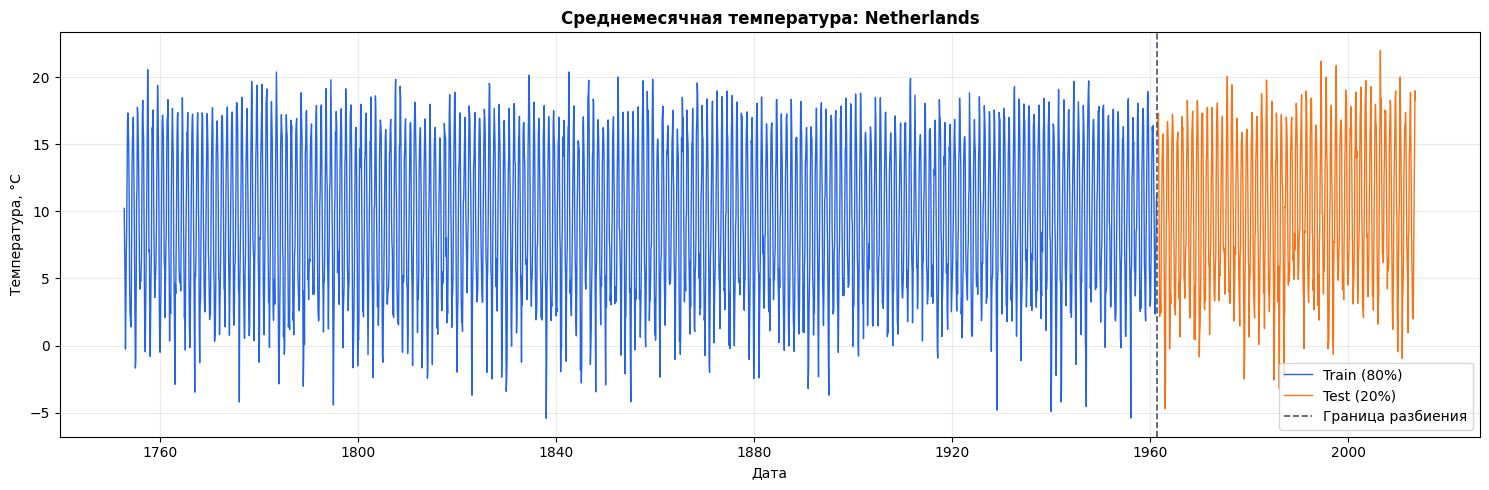

In [24]:
split_position = int(len(temperature) * 0.8)
train = temperature.iloc[:split_position]
test = temperature.iloc[split_position:]

print(f"Train: {len(train)} месяцев ({train.index.min().date()} — {train.index.max().date()})")
print(f"Test:  {len(test)} месяцев ({test.index.min().date()} — {test.index.max().date()})")
print(f"Доли:  {len(train) / len(temperature):.1%} / {len(test) / len(temperature):.1%}")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(train.index, train, label="Train (80%)", color="#2563eb", linewidth=1)
ax.plot(test.index, test, label="Test (20%)", color="#f97316", linewidth=1)
ax.axvline(test.index[0], color="#475569", linestyle="--", linewidth=1.2, label="Граница разбиения")
ax.set(title=f"Среднемесячная температура: {COUNTRY}", xlabel="Дата", ylabel="Температура, °C")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Rolling-window-разбиение

На обучающей части формируем скользящие сплиты: длина обучающего окна — 120 месяцев, горизонт прогноза — 12 месяцев, шаг сдвига — 12 месяцев. Так обучающее окно остаётся фиксированным и движется вперёд по времени.

In [25]:
def rolling_window_splits(series, train_size=120, horizon=12, step=12):
    # Возвращает позиционные индексы train и forecast для каждого окна.
    for train_start in range(0, len(series) - train_size - horizon + 1, step):
        train_end = train_start + train_size
        forecast_end = train_end + horizon
        yield (
            np.arange(train_start, train_end),
            np.arange(train_end, forecast_end),
        )


splits = list(rolling_window_splits(train, train_size=120, horizon=12, step=12))
print(f"Получено сплитов: {len(splits)}")
print(f"Размеры первого сплита: train={len(splits[0][0])}, forecast={len(splits[0][1])}")

Получено сплитов: 198
Размеры первого сплита: train=120, forecast=12


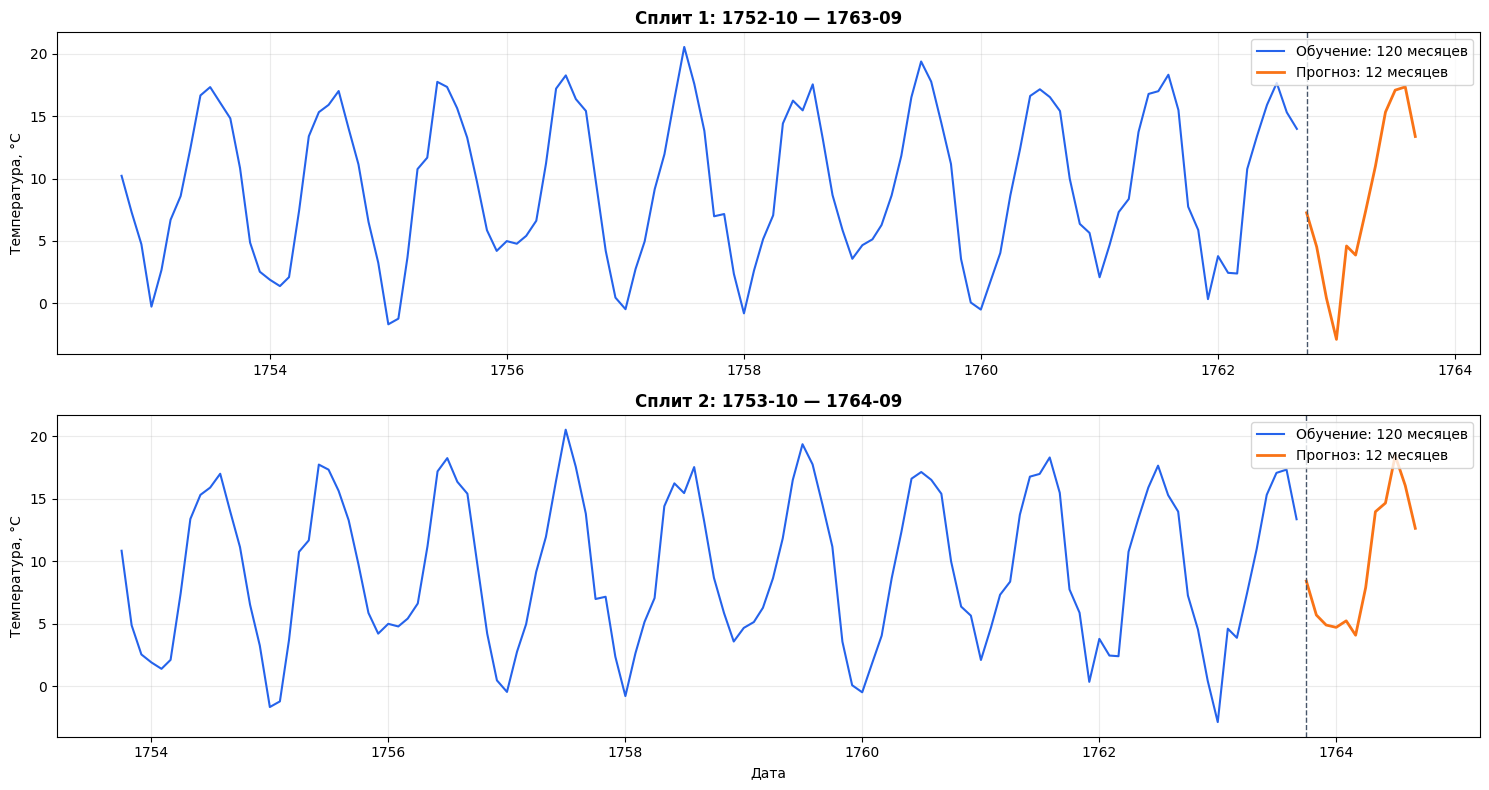

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

for split_number, (ax, (train_idx, forecast_idx)) in enumerate(
    zip(axes, splits[:2]), start=1
):
    split_train = train.iloc[train_idx]
    split_forecast = train.iloc[forecast_idx]

    ax.plot(split_train.index, split_train, color="#2563eb", label="Обучение: 120 месяцев")
    ax.plot(split_forecast.index, split_forecast, color="#f97316", linewidth=2, label="Прогноз: 12 месяцев")
    ax.axvline(split_forecast.index[0], color="#475569", linestyle="--", linewidth=1)
    ax.set(
        title=(
            f"Сплит {split_number}: {split_train.index.min().strftime('%Y-%m')} — "
            f"{split_forecast.index.max().strftime('%Y-%m')}"
        ),
        ylabel="Температура, °C",
    )
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Дата")
plt.tight_layout()
plt.show()

На графиках видно, что второй сплит сдвинут на год: обучение по-прежнему занимает 10 лет, а следующие 12 месяцев образуют прогнозный участок. При этом граница между обучением и прогнозом никогда не нарушает хронологию.

## 4. Генерация признаков

Создаём лаги на 1 и 12 месяцев, номер календарного месяца и бинарный признак зимы (декабрь, январь, февраль). Первые 12 строк с неизвестными лагами удаляем.

In [27]:
feature_df = pd.DataFrame(index=temperature.index)
feature_df["temperature"] = temperature
feature_df["lag_1"] = temperature.shift(1)
feature_df["lag_12"] = temperature.shift(12)
feature_df["month"] = feature_df.index.month
feature_df["is_winter"] = feature_df.index.month.isin([12, 1, 2]).astype(int)
feature_df = feature_df.dropna().copy()

print(f"Размер таблицы признаков: {feature_df.shape}")
display(feature_df.head(12).round(3))

Размер таблицы признаков: (3119, 5)


,temperature,lag_1,lag_12,month,is_winter
dt,,,,,
1753-10-01,10.846,14.827,10.223,10,0
1753-11-01,4.872,10.846,7.301,11,0
1753-12-01,2.538,4.872,4.740,12,1
1754-01-01,1.897,2.538,-0.260,1,1
1754-02-01,1.386,1.897,2.682,2,1
1754-03-01,2.104,1.386,6.699,3,0
1754-04-01,7.420,2.104,8.599,4,0
1754-05-01,13.391,7.420,12.412,5,0
1754-06-01,15.323,13.391,16.663,6,0


`lag_1` содержит температуру предыдущего месяца, а `lag_12` — температуру того же месяца годом ранее. Календарные признаки дополнительно описывают сезонность.

## 5. Линейная регрессия и прогноз на test

Модель обучается только на обучающем участке исходного holdout-разбиения. Для тестовых наблюдений используются фактические прошлые значения в лагах, то есть оценивается одношаговый прогноз при известной истории, а не рекурсивный прогноз на много лет вперёд.

In [28]:
feature_columns = ["lag_1", "lag_12", "month", "is_winter"]

train_features = feature_df.loc[:train.index[-1]].copy()
test_features = feature_df.loc[test.index].copy()

X_train = train_features[feature_columns]
y_train = train_features["temperature"]
X_test = test_features[feature_columns]
y_test = test_features["temperature"]

model = LinearRegression()
model.fit(X_train, y_train)

forecast = pd.Series(model.predict(X_test), index=test.index, name="forecast")
comparison = pd.concat([y_test.rename("actual"), forecast], axis=1)

print("Коэффициенты модели:")
display(pd.Series(model.coef_, index=feature_columns, name="coefficient").to_frame().round(4))
display(comparison.head().round(3))

Коэффициенты модели:


,coefficient
lag_1,0.3416
lag_12,0.6120
month,-0.2056
is_winter,-1.2995


,actual,forecast
dt,,
1961-06-01,15.730,14.708
1961-07-01,15.862,15.758
1961-08-01,16.459,15.897
1961-09-01,17.300,14.631
1961-10-01,12.082,12.741


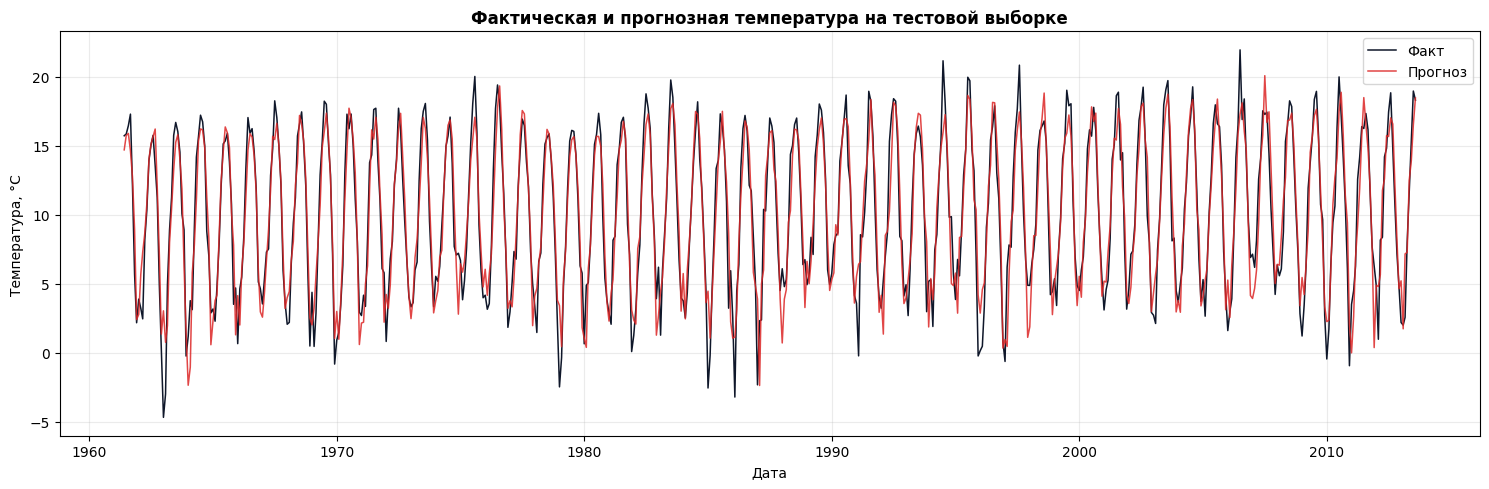

In [29]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(comparison.index, comparison["actual"], label="Факт", color="#0f172a", linewidth=1.1)
ax.plot(comparison.index, comparison["forecast"], label="Прогноз", color="#dc2626", linewidth=1.1, alpha=0.85)
ax.set(title="Фактическая и прогнозная температура на тестовой выборке", xlabel="Дата", ylabel="Температура, °C")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Оценка качества

MAE показывает среднюю абсолютную ошибку, RMSE сильнее штрафует крупные ошибки, а MAPE выражает ошибку в процентах относительно фактического значения.

In [30]:
mae = mean_absolute_error(y_test, forecast)
rmse = np.sqrt(mean_squared_error(y_test, forecast))
mape = mean_absolute_percentage_error(y_test, forecast) * 100

metrics = pd.DataFrame({
    "Метрика": ["MAE, °C", "RMSE, °C", "MAPE, %"],
    "Значение": [mae, rmse, mape],
})
display(metrics.round(3))

,Метрика,Значение
0,"MAE, °C",1.484
1,"RMSE, °C",1.929
2,"MAPE, %",51.472


Линейная регрессия воспроизводит сезонный ход температуры: средняя абсолютная ошибка составляет около **1,48 °C**, а RMSE — около **1,93 °C**. MAPE равна примерно **51,47%**; эта метрика менее устойчива для температур в Цельсиях из-за значений, близких к нулю, поэтому дополнительно ориентируемся на MAE и RMSE.